# Tutorial 5: Composing Connectors and Multi-Compartment Connectivity

The previous tutorials generated one connectivity pattern at a time for point neurons. This tutorial covers two features that build on that:

1. **Composing connectors** with operators: union (`+`), intersection (`*`), difference (`-`), and weight/delay scaling.
2. **Multi-compartment connectivity**, where every edge also records *which compartment* it leaves from and *which compartment* it lands on: soma, basal dendrite, apical dendrite, or axon.

Both features return the same `ConnectionResult` you already know, so the inspection tools from Tutorials 1-4 still apply.

---

## 1. Imports

In [1]:
import warnings

import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

from braintools import conn, visualize as vis
from braintools.init import Constant, Normal

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["font.size"] = 10

print("Imports successful")

Imports successful


## 2. Helper Functions

`edge_set` turns a result into a Python set of `(pre, post)` pairs, which makes it easy to check the operators against ordinary set algebra. `as_plain` strips units before plotting.

In [2]:
def as_plain(values):
    """Return a NumPy array of mantissas for arrays or brainunit quantities."""
    return np.asarray(u.get_mantissa(values))


def edge_list(result):
    """List of (pre, post) neuron pairs, in edge order."""
    return list(zip(result.pre_indices.tolist(), result.post_indices.tolist()))


def edge_set(result):
    """Set of (pre, post) neuron pairs in a ConnectionResult."""
    return set(edge_list(result))


def unique_values(values, decimals=3):
    """Sorted distinct mantissas, for compact printing."""
    return sorted(set(np.round(as_plain(values), decimals).tolist()))

---

## 3. Composing Connectors

Every connector supports a small algebra. The operators do not generate anything immediately; they return a new connector that generates both operands and combines the results when it is called.

| Expression | Result type | Edges kept |
|---|---|---|
| `a + b` | `CompositeConnectivity` | union: edges in `a` or `b` (duplicates removed) |
| `a * b` | `CompositeConnectivity` | intersection: edges in both `a` and `b` |
| `a - b` | `CompositeConnectivity` | difference: edges in `a` but not in `b` |
| `a * 0.5`, `a.weight_scale(0.5)` | `ScaledConnectivity` | all edges of `a`, weights scaled |
| `a.delay_scale(2.0)` | `ScaledConnectivity` | all edges of `a`, delays scaled |

Both operands are called with the same `pre_size`, `post_size`, and positions, so they must describe the same pair of populations.

The example combines a weighted random projection with a deterministic local ring. The ring has no weights of its own, so it acts as a *mask*.

In [3]:
n = 60

random_proj = conn.Random(
    prob=0.15,
    weight=Normal(mean=1.0 * u.nS, std=0.2 * u.nS),
    delay=Constant(2.0 * u.ms),
    seed=42,
)
local_ring = conn.Ring(neighbors=6)  # unweighted: a pure topology mask

random_result = random_proj(pre_size=n, post_size=n)
ring_result = local_ring(pre_size=n, post_size=n)

union = random_proj + local_ring
intersection = random_proj * local_ring
difference = random_proj - local_ring

union_result = union(pre_size=n, post_size=n)
intersection_result = intersection(pre_size=n, post_size=n)
difference_result = difference(pre_size=n, post_size=n)

R, L = edge_set(random_result), edge_set(ring_result)
print(f"operator type: {type(union).__name__}")
print(f"random: {random_result.n_connections} edges, ring: {ring_result.n_connections} edges")
print()
for name, result, expected in [
    ("union        a + b", union_result, R | L),
    ("intersection a * b", intersection_result, R & L),
    ("difference   a - b", difference_result, R - L),
]:
    print(f"{name}: {result.n_connections:4d} edges, matches set algebra: {edge_set(result) == expected}")

operator type: CompositeConnectivity
random: 555 edges, ring: 720 edges

union        a + b: 1167 edges, matches set algebra: True
intersection a * b:  108 edges, matches set algebra: True
difference   a - b:  447 edges, matches set algebra: True


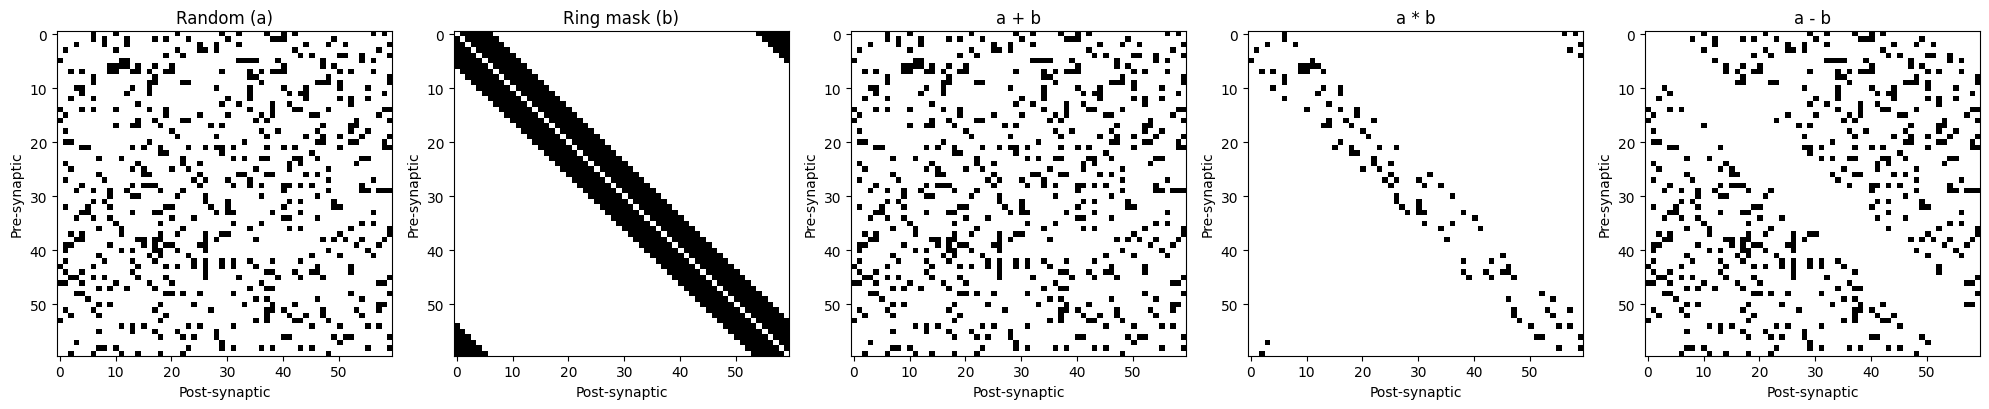

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))
for ax, (title, result) in zip(axes, [
    ("Random (a)", random_result),
    ("Ring mask (b)", ring_result),
    ("a + b", union_result),
    ("a * b", intersection_result),
    ("a - b", difference_result),
]):
    vis.connectivity_matrix(
        (as_plain(result.weight2dense()) != 0).astype(float),
        cmap="binary",
        center_zero=False,
        show_colorbar=False,
        ax=ax,
        title=title,
    )
plt.tight_layout()
plt.show()

Note that the union panel is built from non-zero *weights*, and it looks identical to the random panel: the ring-only edges are present in the result but carry weight `0`. The next section explains why.

### How Weights and Delays Are Combined

The edge sets follow set algebra exactly, but the per-edge values need rules:

- **Union (`a + b`)**: an edge present in both operands keeps the values of the **left** operand. If only one operand has weights (or delays), edges contributed solely by the other operand get weight `0` (delay `0`). Give both operands weights when you need every edge to be effective.
- **Intersection (`a * b`)**: weights are **multiplied** and delays are **averaged**. An operand without weights counts as `1` and an operand without delays is ignored, so intersecting with an unweighted mask keeps the weighted operand's values unchanged. If both operands carry weights the units multiply too (`nS * nS = nS^2`), which is rarely what you want.
- **Difference (`a - b`)**: kept edges retain the left operand's weights and delays.

In [5]:
# Intersection with an unweighted mask keeps the original weights and delays.
random_weights = dict(zip(edge_list(random_result), as_plain(random_result.weights).tolist()))
same_weights = all(
    np.isclose(random_weights[edge], w)
    for edge, w in zip(edge_list(intersection_result), as_plain(intersection_result.weights))
)
print("a * mask")
print(f"  weight unit: {u.get_unit(intersection_result.weights)}")
print(f"  weights equal to the random projection's: {same_weights}")
print(f"  delays: {unique_values(intersection_result.delays)} {u.get_unit(intersection_result.delays)}")

# Union: edges that only the unweighted ring contributed carry weight 0.
ring_only = np.array([edge not in R for edge in edge_list(union_result)])
print()
print("a + mask")
print(f"  edges contributed only by the ring: {int(ring_only.sum())}")
print(f"  their weights: {unique_values(union_result.weights[ring_only])} {u.get_unit(union_result.weights)}")

# Two weighted operands: the units multiply.
weighted_ring = conn.Ring(neighbors=6, weight=Constant(2.0 * u.nS))
both_weighted = (random_proj * weighted_ring)(pre_size=n, post_size=n)
print()
print("a * weighted b")
print(f"  weight unit: {u.get_unit(both_weighted.weights)}")

a * mask
  weight unit: nS
  weights equal to the random projection's: True
  delays: [2.0] ms

a + mask
  edges contributed only by the ring: 612
  their weights: [0.0] nS

a * weighted b
  weight unit: nS^2


### Scaling Weights and Delays

Multiplying a connector by a number scales its weights. The number must be on the **right** (`pattern * 0.5`); `0.5 * pattern` raises `TypeError`. `weight_scale()` and `delay_scale()` are the explicit forms. Scaling returns a new connector and never modifies the base connector's cached result.

In [6]:
half_weights = random_proj * 0.5
slow = random_proj.delay_scale(1.5)

half_result = half_weights(pre_size=n, post_size=n)
slow_result = slow(pre_size=n, post_size=n)
base_again = random_proj(pre_size=n, post_size=n)

print(f"scaled type: {type(half_weights).__name__}")
print(f"mean weight  base: {u.math.mean(base_again.weights):.3f}  x0.5: {u.math.mean(half_result.weights):.3f}")
print(f"delays       base: {unique_values(base_again.delays)} ms  x1.5: {unique_values(slow_result.delays)} ms")
print(f"same edges after scaling: {edge_set(half_result) == edge_set(base_again)}")

try:
    0.5 * random_proj
except TypeError as exc:
    print(f"0.5 * pattern -> TypeError: {exc}")

scaled type: ScaledConnectivity
mean weight  base: 0.994 nS  x0.5: 0.497 nS
delays       base: [2.0] ms  x1.5: [3.0] ms
same edges after scaling: True
0.5 * pattern -> TypeError: unsupported operand type(s) for *: 'float' and 'Random'


### Building a Projection from Parts

Operators compose, so small building blocks can describe a structured projection. Here a dense local neighbourhood is joined with sparse long-range shortcuts, and the long-range part is weakened before the union. The `- local_mask` term keeps the shortcuts outside the neighbourhood, so every edge in the result comes from exactly one source.

local edges:    399
shortcut edges: 90
composite:      489 edges
weight values:  [0.3, 1.0] nS


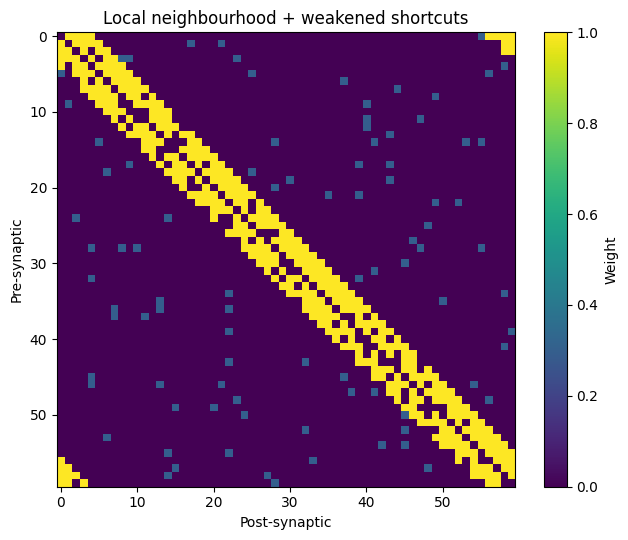

In [7]:
local_mask = conn.Ring(neighbors=4)
local = conn.Random(prob=0.8, weight=Constant(1.0 * u.nS), seed=1) * local_mask
shortcuts = (conn.Random(prob=0.03, weight=Constant(1.0 * u.nS), seed=2) - local_mask) * 0.3

composite = local + shortcuts
composite_result = composite(pre_size=n, post_size=n)

print(f"local edges:    {local(pre_size=n, post_size=n).n_connections}")
print(f"shortcut edges: {shortcuts(pre_size=n, post_size=n).n_connections}")
print(f"composite:      {composite_result.n_connections} edges")
print(f"weight values:  {unique_values(composite_result.weights)} nS")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
vis.connectivity_matrix(
    as_plain(composite_result.weight2dense()),
    cmap="viridis",
    center_zero=False,
    show_colorbar=True,
    ax=ax,
    title="Local neighbourhood + weakened shortcuts",
)
plt.tight_layout()
plt.show()

---

## 4. Multi-Compartment Connectivity

Multi-compartment connectors describe synapses between neurons with morphology. Compartments are identified by integer constants exported from `braintools.conn`:

| Constant | Value | Name used in mappings |
|---|---|---|
| `conn.SOMA` | 0 | `'soma'` |
| `conn.BASAL_DENDRITE` | 1 | `'basal_dendrite'` |
| `conn.APICAL_DENDRITE` | 2 | `'apical_dendrite'` |
| `conn.AXON` | 3 | `'axon'` |

A multi-compartment result has `model_type == 'multi_compartment'` and two extra per-edge arrays, `pre_compartments` and `post_compartments`, aligned with `pre_indices` and `post_indices`. The neuron indices still refer to whole neurons.

In [8]:
COMPARTMENT_NAMES = {
    conn.SOMA: "soma",
    conn.BASAL_DENDRITE: "basal",
    conn.APICAL_DENDRITE: "apical",
    conn.AXON: "axon",
}


def compartment_counts(result):
    """Number of edges for each (pre compartment, post compartment) pair."""
    pairs, counts = np.unique(
        np.stack([result.pre_compartments, result.post_compartments], axis=1),
        axis=0,
        return_counts=True,
    )
    return {
        f"{COMPARTMENT_NAMES[int(pre)]} -> {COMPARTMENT_NAMES[int(post)]}": int(count)
        for (pre, post), count in zip(pairs, counts)
    }


def summarize_compartments(name, result):
    print(name)
    print("=" * len(name))
    print(f"model_type: {result.model_type}")
    print(f"shape: {result.shape}, connections: {result.n_connections}")
    for pair, count in compartment_counts(result).items():
        print(f"  {pair:<16s} {count}")

## 5. `CompartmentSpecific`

`CompartmentSpecific` is the general connector. `compartment_mapping` maps a source compartment to one target or a list of targets, using either the integer constants or the names above. `connection_prob` is a single probability for every mapped pair, or a dict keyed by `(source, target)`.

Each mapped pair is sampled independently, so the same neuron pair can appear more than once with different target compartments, just as one axon can contact both the soma and a dendrite of the same cell. As with point connectors, self-connections are dropped by default when `pre_size == post_size`; pass `allow_self_connections=True` to keep them.

In [9]:
axon_targets = conn.CompartmentSpecific(
    compartment_mapping={conn.AXON: [conn.SOMA, conn.BASAL_DENDRITE, conn.APICAL_DENDRITE]},
    connection_prob={
        (conn.AXON, conn.SOMA): 0.02,
        (conn.AXON, conn.BASAL_DENDRITE): 0.10,
        (conn.AXON, conn.APICAL_DENDRITE): 0.05,
    },
    weight=Normal(mean=1.0 * u.nS, std=0.1 * u.nS),
    delay=Constant(1.0 * u.ms),
    seed=0,
)
axon_result = axon_targets(pre_size=100, post_size=100)

summarize_compartments("CompartmentSpecific with per-pair probabilities", axon_result)
print()
print("first edges (pre neuron/compartment -> post neuron/compartment):")
for i in range(4):
    print(
        f"  {axon_result.pre_indices[i]:>3d}/{COMPARTMENT_NAMES[int(axon_result.pre_compartments[i])]:<6s}"
        f" -> {axon_result.post_indices[i]:>3d}/{COMPARTMENT_NAMES[int(axon_result.post_compartments[i])]}"
    )

pairs = edge_list(axon_result)
print()
print(f"neuron pairs contacted on more than one compartment: {len(pairs) - len(set(pairs))}")

CompartmentSpecific with per-pair probabilities
model_type: multi_compartment
shape: (100, 100), connections: 1803


  axon -> soma     226
  axon -> basal    1077
  axon -> apical   500

first edges (pre neuron/compartment -> post neuron/compartment):
    0/axon   ->  34/soma
    0/axon   ->  99/soma
    1/axon   ->  26/soma
    1/axon   ->  66/soma

neuron pairs contacted on more than one compartment: 95


Names work as well as constants. When `connection_prob` is a dict, every mapped pair needs an entry: a missing pair is dropped with a `UserWarning` rather than silently ignored.

In [10]:
named = conn.CompartmentSpecific(
    compartment_mapping={"axon": ["basal_dendrite", "apical_dendrite"]},
    connection_prob=0.05,
    seed=0,
)
summarize_compartments("Named mapping", named(pre_size=100, post_size=100))

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    partial = conn.CompartmentSpecific(
        compartment_mapping={conn.AXON: [conn.SOMA, conn.BASAL_DENDRITE]},
        connection_prob={(conn.AXON, conn.SOMA): 0.05},  # (AXON, BASAL_DENDRITE) missing
        seed=0,
    )(pre_size=100, post_size=100)
print()
print(f"warning: {caught[0].message}")
print(f"target compartments present: {sorted(COMPARTMENT_NAMES[int(c)] for c in np.unique(partial.post_compartments))}")

Named mapping
model_type: multi_compartment
shape: (100, 100), connections: 1073
  axon -> basal    519
  axon -> apical   554

target compartments present: ['soma']


## 6. Anatomical Shortcuts

Common mappings have dedicated subclasses. They accept the same keyword arguments as `CompartmentSpecific` (`connection_prob`, `weight`, `delay`, `allow_self_connections`, `seed`, ...).

| Connector | Mapping |
|---|---|
| `AxonToSoma` | axon -> soma |
| `AxonToDendrite(target_dendrites=...)` | axon -> basal and apical dendrites (default) |
| `DendriteToSoma(source_dendrites=...)` | basal and apical dendrites -> soma |
| `SomaToDendrite(target_dendrites=..., prob_per_dendrite=...)` | soma -> dendrites, optionally with one probability per dendrite |
| `DendriteToDendrite` | basal/apical -> basal/apical |
| `BasalDendriteTargeting`, `ApicalDendriteTargeting` | axon -> one dendrite type |
| `ProximalTargeting`, `DistalTargeting` | axon -> basal (proximal) or apical (distal) dendrites |
| `AllToAllCompartments` | every compartment -> every compartment |

In [11]:
shortcut_connectors = {
    "AxonToSoma": conn.AxonToSoma(connection_prob=0.05, seed=0),
    "AxonToDendrite (basal only)": conn.AxonToDendrite(
        target_dendrites=[conn.BASAL_DENDRITE], connection_prob=0.05, seed=0
    ),
    "DendriteToSoma": conn.DendriteToSoma(connection_prob=0.05, seed=0),
    "SomaToDendrite (per-dendrite prob)": conn.SomaToDendrite(
        prob_per_dendrite={conn.BASAL_DENDRITE: 0.08, conn.APICAL_DENDRITE: 0.02}, seed=0
    ),
}

for name, pattern in shortcut_connectors.items():
    summarize_compartments(name, pattern(pre_size=80, post_size=80))
    print()

AxonToSoma
model_type: multi_compartment
shape: (80, 80), connections: 321
  axon -> soma     321

AxonToDendrite (basal only)
model_type: multi_compartment
shape: (80, 80), connections: 321
  axon -> basal    321

DendriteToSoma
model_type: multi_compartment
shape: (80, 80), connections: 661
  basal -> soma    321
  apical -> soma   340

SomaToDendrite (per-dendrite prob)
model_type: multi_compartment
shape: (80, 80), connections: 640
  soma -> basal    509
  soma -> apical   131



## 7. Inspecting Compartment Results

`weight2dense()` and `delay2matrix()` work on neuron indices only. When one neuron pair is connected on several compartments, those edges share one matrix cell and only one value survives. To keep compartment information, build one matrix per target compartment yourself. `np.add.at` sums correctly when the same cell appears more than once.

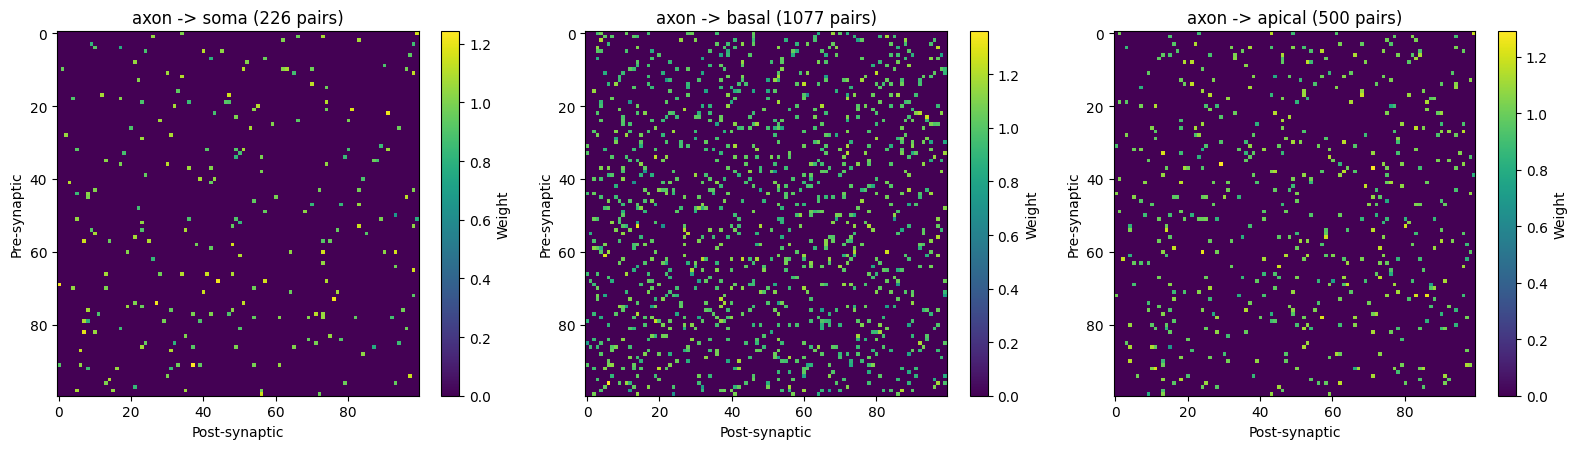

sum of per-compartment matrices equals total weight: True
dense neuron-level matrix keeps 1708 of 1803 edges


In [12]:
def compartment_matrix(result, post_compartment):
    """Summed weights per neuron pair onto one target compartment."""
    keep = result.post_compartments == post_compartment
    matrix = np.zeros(result.shape)
    weights = np.ones(result.n_connections) if result.weights is None else as_plain(result.weights)
    np.add.at(matrix, (result.pre_indices[keep], result.post_indices[keep]), weights[keep])
    return matrix


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, comp in zip(axes, [conn.SOMA, conn.BASAL_DENDRITE, conn.APICAL_DENDRITE]):
    matrix = compartment_matrix(axon_result, comp)
    vis.connectivity_matrix(
        matrix,
        cmap="viridis",
        center_zero=False,
        show_colorbar=True,
        ax=ax,
        title=f"axon -> {COMPARTMENT_NAMES[comp]} ({int((matrix != 0).sum())} pairs)",
    )
plt.tight_layout()
plt.show()

total_by_compartment = sum(compartment_matrix(axon_result, c).sum() for c in COMPARTMENT_NAMES)
print(f"sum of per-compartment matrices equals total weight: "
      f"{np.isclose(total_by_compartment, as_plain(axon_result.weights).sum())}")
print(f"dense neuron-level matrix keeps {int((as_plain(axon_result.weight2dense()) != 0).sum())} "
      f"of {axon_result.n_connections} edges")

## 8. Distance-Dependent Compartment Targeting

`MorphologyDistance` makes the connection probability decay with the distance between the neurons' positions (`pre_positions` / `post_positions`, required). `decay_function` is `'gaussian'`, `'exponential'`, or `'linear'`, and `sigma` sets the length scale. `compartment_mapping` chooses the compartments (axon -> basal and apical dendrites by default); each mapped pair is sampled independently with the same distance profile.

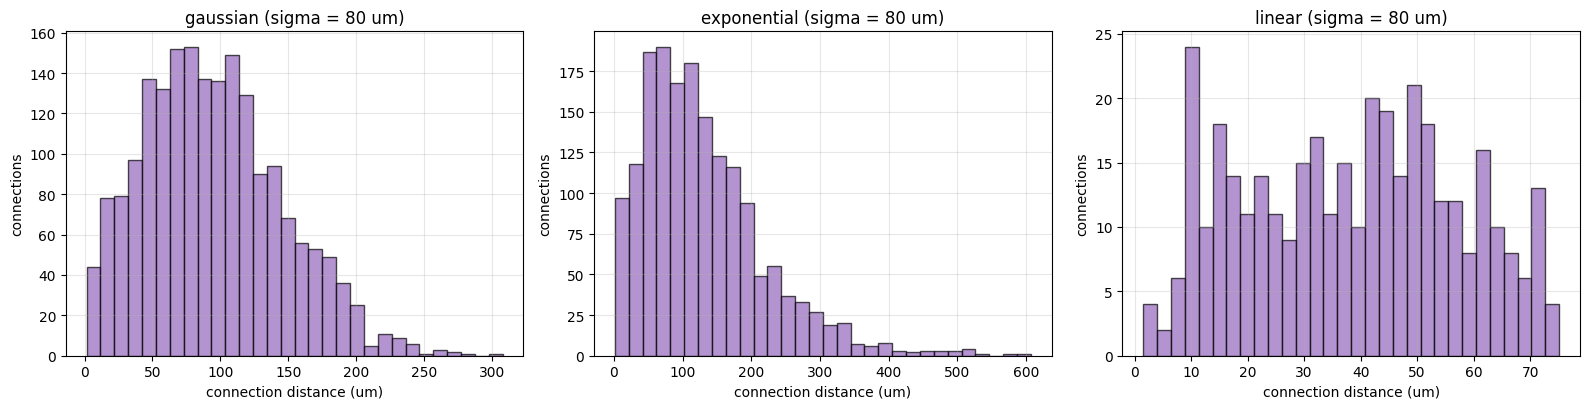

gaussian     connections:  1933   max distance:  307.9 um   compartments: ['axon -> basal']
exponential  connections:  1702   max distance:  607.1 um   compartments: ['axon -> basal']
linear       connections:   372   max distance:   75.1 um   compartments: ['axon -> basal']


In [13]:
rng = np.random.default_rng(0)
cell_positions = rng.uniform(0.0, 600.0, (150, 2)) * u.um

morph_results = {}
for decay in ["gaussian", "exponential", "linear"]:
    morph_results[decay] = conn.MorphologyDistance(
        sigma=80.0 * u.um,
        decay_function=decay,
        compartment_mapping={conn.AXON: conn.BASAL_DENDRITE},
        weight=Constant(1.0 * u.nS),
        seed=0,
    )(
        pre_size=150,
        post_size=150,
        pre_positions=cell_positions,
        post_positions=cell_positions,
    )

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (decay, result) in zip(axes, morph_results.items()):
    vis.distribution_plot(
        as_plain(result.get_distances()),
        bins=30,
        density=False,
        alpha=0.7,
        colors=["tab:purple"],
        edgecolor="black",
        ax=ax,
        xlabel="connection distance (um)",
        ylabel="connections",
        title=f"{decay} (sigma = 80 um)",
    )
plt.tight_layout()
plt.show()

for decay, result in morph_results.items():
    print(f"{decay:<12s} connections: {result.n_connections:5d}   "
          f"max distance: {as_plain(result.get_distances()).max():6.1f} um   "
          f"compartments: {list(compartment_counts(result))}")

The linear profile reaches zero at `sigma`, so it never connects neurons further apart than 80 um, while the Gaussian and exponential profiles only become small.

## 9. Dendritic Trees and Axonal Projections

`DendriticTree` generates axon -> dendrite edges with two independent probabilities: `branch_targeting['proximal']` for basal dendrites and `branch_targeting['distal']` for apical dendrites. The names describe the usual anatomy; the connector does not model positions along a branch.

`AxonalProjection` draws axon -> dendrite edges and assigns each one a random compartment from `target_compartments`. The probability of each neuron pair is built from up to two spatial terms, both of which need positions:

- `topographic_map(pre_xy, post_xy)` replaces the uniform `connection_prob`. The map receives one row of each position array as plain numbers in the unit of `pre_positions`.
- `arborization_sigma` multiplies the probability by `exp(-d**2 / (2 * sigma**2))`, confining each axon's arbor to a local field.

Without either term every pair uses `connection_prob`.

In [14]:
tree_result = conn.DendriticTree(
    branch_targeting={"proximal": 0.15, "distal": 0.05},
    weight=Constant(0.8 * u.nS),
    seed=0,
)(pre_size=100, post_size=100)
summarize_compartments("DendriticTree", tree_result)
print()


def retinotopic(pre_xy, post_xy, width=60.0):
    """Connection probability peaking where source and target share a position."""
    d2 = np.sum((pre_xy - post_xy) ** 2)
    return 0.6 * np.exp(-d2 / (2 * width ** 2))


source_positions = rng.uniform(0.0, 600.0, (80, 2)) * u.um
target_positions = rng.uniform(0.0, 600.0, (80, 2)) * u.um

projection_result = conn.AxonalProjection(
    topographic_map=retinotopic,
    target_compartments=[conn.APICAL_DENDRITE],
    weight=Constant(1.0 * u.nS),
    seed=0,
)(
    pre_size=80,
    post_size=80,
    pre_positions=source_positions,
    post_positions=target_positions,
)
summarize_compartments("AxonalProjection with a topographic map", projection_result)
print(f"mean projection distance: {as_plain(projection_result.get_distances()).mean():.1f} um")
print()

for sigma in [None, 150.0 * u.um, 50.0 * u.um]:
    arbor_result = conn.AxonalProjection(
        connection_prob=0.5,
        arborization_sigma=sigma,
        seed=0,
    )(
        pre_size=80,
        post_size=80,
        pre_positions=source_positions,
        post_positions=target_positions,
    )
    print(f"arborization_sigma={str(sigma):<10s} connections: {arbor_result.n_connections:4d}   "
          f"mean distance: {as_plain(arbor_result.get_distances()).mean():6.1f} um")

DendriticTree
model_type: multi_compartment
shape: (100, 100), connections: 2097
  axon -> basal    1543
  axon -> apical   554

AxonalProjection with a topographic map
model_type: multi_compartment
shape: (80, 80), connections: 229
  axon -> apical   229
mean projection distance: 79.3 um

arborization_sigma=None       connections: 3208   mean distance:  296.1 um
arborization_sigma=150. um    connections:  916   mean distance:  161.6 um
arborization_sigma=50. um     connections:  127   mean distance:   66.7 um


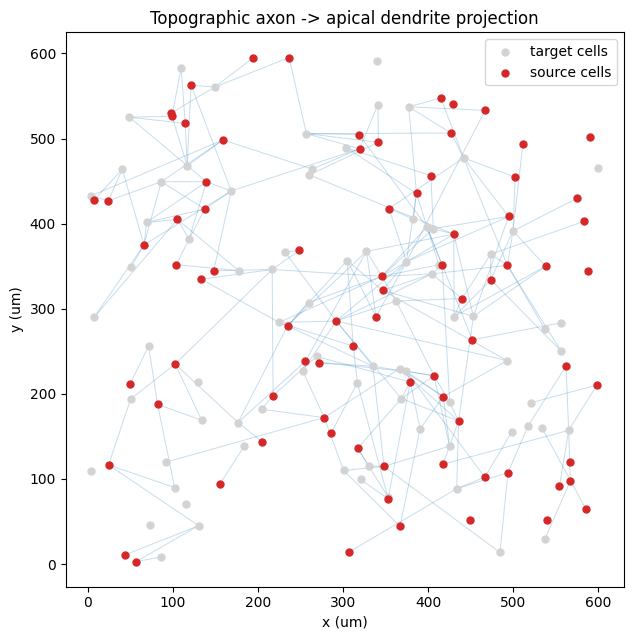

In [15]:
src_xy = as_plain(source_positions)
dst_xy = as_plain(target_positions)

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.scatter(dst_xy[:, 0], dst_xy[:, 1], s=25, c="lightgray", label="target cells", zorder=1)
ax.scatter(src_xy[:, 0], src_xy[:, 1], s=25, c="tab:red", label="source cells", zorder=2)
for pre, post in edge_list(projection_result):
    ax.plot([src_xy[pre, 0], dst_xy[post, 0]], [src_xy[pre, 1], dst_xy[post, 1]],
            color="tab:blue", alpha=0.25, linewidth=0.7, zorder=0)
ax.set_xlabel("x (um)")
ax.set_ylabel("y (um)")
ax.set_title("Topographic axon -> apical dendrite projection")
ax.set_aspect("equal")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 10. Synapse Placement

`SynapticPlacement` separates *whether* two neurons connect from *where* the synapse lands. Each neuron pair forms one synapse with probability `connection_prob`, and each synapse is then placed on a compartment drawn in proportion to `compartment_preferences`. Placement rules are just different preference dicts: proximal-only input targets the basal dendrites, distal input the apical dendrites, and perisomatic input the soma.

The three projections below share `connection_prob` and the seed, so they connect exactly the same neuron pairs; only the location of the synapses differs.

proximal  synapses:  2321   soma=0.00  basal=1.00  apical=0.00
distal    synapses:  2321   soma=0.00  basal=0.19  apical=0.81
mixed     synapses:  2321   soma=0.21  basal=0.50  apical=0.29


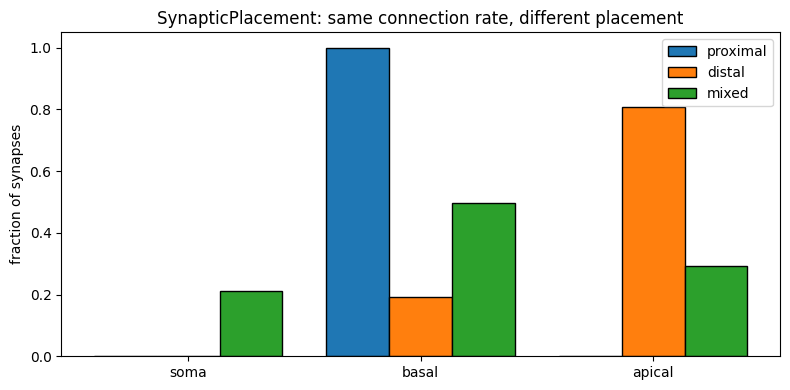

In [16]:
placement_rules = {
    "proximal": {conn.BASAL_DENDRITE: 1.0},
    "distal": {conn.APICAL_DENDRITE: 0.8, conn.BASAL_DENDRITE: 0.2},
    "mixed": {conn.SOMA: 0.2, conn.BASAL_DENDRITE: 0.5, conn.APICAL_DENDRITE: 0.3},
}

placement_fractions = {}
for rule, preferences in placement_rules.items():
    placed = conn.SynapticPlacement(
        connection_prob=0.1,
        compartment_preferences=preferences,
        seed=0,
    )(pre_size=150, post_size=150)
    counts = np.bincount(placed.post_compartments, minlength=4)
    placement_fractions[rule] = counts / counts.sum()
    print(f"{rule:<9s} synapses: {placed.n_connections:5d}   " + "  ".join(
        f"{COMPARTMENT_NAMES[c]}={placement_fractions[rule][c]:.2f}" for c in (conn.SOMA, conn.BASAL_DENDRITE, conn.APICAL_DENDRITE)
    ))

fig, ax = plt.subplots(figsize=(8, 4))
targets = [conn.SOMA, conn.BASAL_DENDRITE, conn.APICAL_DENDRITE]
x = np.arange(len(targets))
for offset, (rule, fractions) in zip([-0.27, 0.0, 0.27], placement_fractions.items()):
    ax.bar(x + offset, fractions[targets], width=0.27, label=rule, edgecolor="black")
ax.set_xticks(x, [COMPARTMENT_NAMES[c] for c in targets])
ax.set_ylabel("fraction of synapses")
ax.set_title("SynapticPlacement: same connection rate, different placement")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Axonal Branching and Arborization

Two connectors describe *how an axon spreads* rather than a per-pair probability:

- `AxonalBranching` gives each axon a Poisson-distributed number of branches (mean `branches_per_axon`), each ending on a different target neuron. Without `branch_spread` the targets are chosen uniformly; with it (positions required) targets are chosen in proportion to `exp(-d**2 / (2 * branch_spread**2))`, so branches stay near the source.
- `AxonalArborization` connects every pair within `arborization_radius` with probability `density`, and nothing beyond it.

Both place synapses on basal or apical dendrites at random. As with the other spatial connectors, a plain-number length is interpreted in the unit of the positions.

AxonalBranching, uniform targets       edges:  1157   mean out-degree:  5.79   mean distance:  513.0 um
AxonalBranching, branch_spread=60 um   edges:  1177   mean out-degree:  5.88   mean distance:   91.2 um
AxonalArborization, radius=120 um      edges:   253   mean out-degree:  1.26   mean distance:   76.0 um


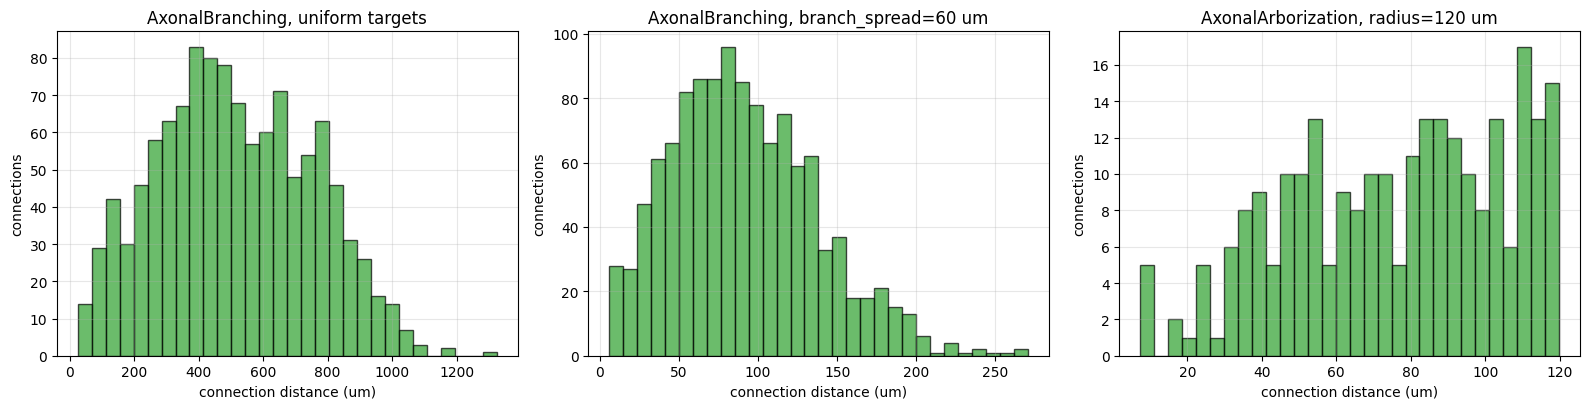

In [17]:
branch_positions = rng.uniform(0.0, 1000.0, (200, 2)) * u.um
branch_call = dict(pre_size=200, post_size=200, pre_positions=branch_positions, post_positions=branch_positions)

axon_patterns = {
    "AxonalBranching, uniform targets": conn.AxonalBranching(branches_per_axon=6, seed=0),
    "AxonalBranching, branch_spread=60 um": conn.AxonalBranching(
        branches_per_axon=6, branch_spread=60.0 * u.um, seed=0
    ),
    "AxonalArborization, radius=120 um": conn.AxonalArborization(
        arborization_radius=120.0 * u.um, density=0.15, seed=0
    ),
}
axon_pattern_results = {name: pattern(**branch_call) for name, pattern in axon_patterns.items()}

for name, result in axon_pattern_results.items():
    out_degree = np.bincount(result.pre_indices, minlength=200)
    print(f"{name:<38s} edges: {result.n_connections:5d}   mean out-degree: {out_degree.mean():5.2f}   "
          f"mean distance: {as_plain(result.get_distances()).mean():6.1f} um")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, result) in zip(axes, axon_pattern_results.items()):
    vis.distribution_plot(
        as_plain(result.get_distances()),
        bins=30,
        density=False,
        alpha=0.7,
        colors=["tab:green"],
        edgecolor="black",
        ax=ax,
        xlabel="connection distance (um)",
        ylabel="connections",
        title=name,
    )
plt.tight_layout()
plt.show()

## 12. Custom Compartment Rules

`CustomCompartment` wraps a function that receives the call arguments as keywords (`pre_size`, `post_size`, `pre_positions`, `post_positions`; positions are `None` when not given) and returns `(pre_indices, post_indices, pre_compartments, post_compartments)`. Optionally append `weights`, or `weights` and `delays`. Plain-number delays are interpreted as milliseconds.

The rule below gives every neuron one input on its soma from its neighbour and one input on its apical dendrite from a neuron half-way around the population.

In [18]:
def neighbour_and_opposite(pre_size, post_size, **kwargs):
    post = np.arange(post_size)
    pre_neighbour = (post - 1) % pre_size
    pre_opposite = (post + pre_size // 2) % pre_size

    pre = np.concatenate([pre_neighbour, pre_opposite])
    post_all = np.concatenate([post, post])
    pre_comp = np.full(pre.size, conn.AXON)
    post_comp = np.concatenate([
        np.full(post_size, conn.SOMA),
        np.full(post_size, conn.APICAL_DENDRITE),
    ])
    weights = np.concatenate([np.full(post_size, 2.0), np.full(post_size, 0.5)]) * u.nS
    delays = np.concatenate([np.full(post_size, 1.0), np.full(post_size, 3.0)])  # ms
    return pre, post_all, pre_comp, post_comp, weights, delays


custom_result = conn.CustomCompartment(neighbour_and_opposite)(pre_size=12, post_size=12)
summarize_compartments("CustomCompartment", custom_result)
print(f"weights: {unique_values(custom_result.weights)} {u.get_unit(custom_result.weights)}")
print(f"delays:  {unique_values(custom_result.delays)} {u.get_unit(custom_result.delays)}")

CustomCompartment
model_type: multi_compartment
shape: (12, 12), connections: 24
  axon -> soma     12
  axon -> apical   12
weights: [0.5, 2.0] nS
delays:  [1.0, 3.0] ms


## 13. Composing Compartment Connectors

The operators from Section 3 also work on multi-compartment connectors, and the compartment arrays are carried through. Edges are compared by neuron pair *and* compartment pair, so an axon -> soma edge and an axon -> dendrite edge between the same two neurons are different edges.

A common use is to model one presynaptic population that targets different compartments with different strengths: strong, fast perisomatic synapses plus weaker, slower dendritic ones.

In [19]:
perisomatic = conn.AxonToSoma(
    connection_prob=0.05,
    weight=Constant(3.0 * u.nS),
    delay=Constant(0.8 * u.ms),
    seed=10,
)
dendritic = conn.AxonToDendrite(
    connection_prob=0.10,
    weight=Constant(0.7 * u.nS),
    delay=Constant(2.0 * u.ms),
    seed=11,
)

combined = perisomatic + dendritic
combined_result = combined(pre_size=100, post_size=100)
summarize_compartments("AxonToSoma + AxonToDendrite", combined_result)

print()
print(f"{'target':<8s} {'mean weight':>12s} {'mean delay':>11s}")
for comp in [conn.SOMA, conn.BASAL_DENDRITE, conn.APICAL_DENDRITE]:
    keep = combined_result.post_compartments == comp
    print(f"{COMPARTMENT_NAMES[comp]:<8s} {as_plain(combined_result.weights)[keep].mean():>9.2f} nS "
          f"{as_plain(combined_result.delays)[keep].mean():>8.2f} ms")

# Removing the perisomatic edges again leaves exactly the dendritic part.
dendritic_only = (combined - perisomatic)(pre_size=100, post_size=100)
print()
print(f"(perisomatic + dendritic) - perisomatic has {dendritic_only.n_connections} edges; "
      f"dendritic alone has {dendritic(pre_size=100, post_size=100).n_connections}")

AxonToSoma + AxonToDendrite
model_type: multi_compartment
shape: (100, 100), connections: 2562
  axon -> soma     562
  axon -> basal    997
  axon -> apical   1003

target    mean weight  mean delay
soma          3.00 nS     0.80 ms
basal         0.70 nS     2.00 ms
apical        0.70 nS     2.00 ms

(perisomatic + dendritic) - perisomatic has 2000 edges; dendritic alone has 2000


---

## 14. Key Takeaways

- `a + b`, `a * b`, and `a - b` combine connectors by union, intersection, and difference of their edges. The operands must describe the same pre/post populations.
- Union keeps the left operand's values on shared edges and gives weight/delay `0` to edges from an operand without them. Intersection multiplies weights and averages delays, and an operand without weights or delays is neutral, so `pattern * unweighted_mask` is the idiomatic way to restrict a projection.
- `pattern * factor`, `weight_scale()`, and `delay_scale()` scale values without touching the base connector; the scalar goes on the right.
- Multi-compartment connectors return `model_type == 'multi_compartment'` results with per-edge `pre_compartments` and `post_compartments` using `SOMA`, `BASAL_DENDRITE`, `APICAL_DENDRITE`, and `AXON`.
- Use `CompartmentSpecific` for arbitrary mappings, the anatomical shortcuts for common ones, `MorphologyDistance`, `AxonalProjection` (`topographic_map`, `arborization_sigma`), `AxonalBranching` (`branch_spread`), and `AxonalArborization` for spatial rules, `SynapticPlacement` to choose where synapses land independently of how many there are, and `CustomCompartment` for anything else.
- `weight2dense()` is neuron-level; build per-compartment matrices when the same neuron pair is connected on several compartments.

For the full list of multi-compartment connectors and their parameters, see the {doc}`API reference <../apis/conn>`.